# V42 — Descriptive Statistics: Sugar-Based Yogurt, Three-Year HMM Sample

**Purpose:** Produce Table 1 (Panels A–D), sample-filter audit, and a presentation figure using the **V42 sugar-yogurt trip panel**. The source Parquet is read-only.

**Five modeled categories:** fruits and vegetables, **sugar-based yogurt**, cereal, snacks, and combined beverages (healthy drinks or qualifying milk). Original `milk_y` values 1/2 take healthy-choice priority in the combined beverage category, preserving V38's five-category convention.

**Sample:** 2008–2017, retaining only households with **at least three distinct observed panel years** in the input parquet. These years need **not** be consecutive. The threshold is computed from the actual input before any summaries; retained trips and household-years are used consistently in all panels and figures. This is an *observed-year eligibility filter*, not a guarantee of matching any additional model-side exclusion rules.

**Yogurt interpretation:** `yogurt_y` is the **new sugar-based choice outcome**, *not* the old fat-free/low-fat classification. The notebook reports code `1` as the preferred sugar-based yogurt choice, as in the original gated-choice convention. Confirm the upstream label coding before interpreting it specifically as "low-sugar." Old fat-based yogurt expenditure columns are neither required nor used to infer the new yogurt coding.

**Statistics:** Household-year demographics weight each retained household-year equally; events use observed household-years after each household's first retained year. Category-purchase incidence is computed over all retained trips; within-category choice proportions are conditional on category purchase, **not** spending shares.

**Input:** `C:/Users/rwen13/Documents/healthy_purchase_data/processed/hmm_input/hmm_estimation_panel_sugar.parquet` (restricted; outside GitHub).

**Outputs:** `healthy_purchase_data/model_outputs/descriptive_statistics/V42_sugar_yogurt_three_year/` for aggregate CSV tables and PNG; DuckDB scratch files under `healthy_purchase_data/temp/`. Review aggregate results before sharing or committing.

**Run:** Python packages `duckdb`, `pandas`, `numpy`, `matplotlib`. Run notebook cells in order on the authorized local computer. No HMM estimation or modification of input files.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import duckdb

DATA_ROOT = Path(r"C:\Users\rwen13\Documents\healthy_purchase_data")
REPO_ROOT = Path(r"C:\Users\rwen13\Documents\healthy_purchase_cycle")
INPUT_PATH = DATA_ROOT / "processed" / "hmm_input" / "hmm_estimation_panel_sugar.parquet"
OUTPUT_ROOT = DATA_ROOT / "model_outputs" / "descriptive_statistics" / "V42_sugar_yogurt_three_year"
TABLE_DIR = OUTPUT_ROOT / "tables"
FIGURE_DIR = OUTPUT_ROOT / "figures"
TEMP_DIR = DATA_ROOT / "temp" / "descriptive_statistics_v42_duckdb"

# V42 eligibility is based on distinct observed panel years per household.
MIN_OBSERVED_YEARS_PER_HOUSEHOLD = 3
DUCKDB_MEMORY_LIMIT = "4GB"
DUCKDB_THREADS = 4
YEAR_START, YEAR_END = 2008, 2017

# Five emission categories, including the existing milk/beverage combination.
CATEGORIES = ["fv", "yogurt", "cereal", "snack", "beverage"]
DISPLAY_NAMES = {
    "fv": "Fruits & Vegetables",
    "yogurt": "Yogurt",
    "cereal": "Breakfast Cereal",
    "snack": "Snacks",
    "beverage": "Beverages (including milk)",
}
HEALTHY_LABELS = {
    "fv": "Fresh FV",
    "yogurt": "Preferred sugar-based yogurt",
    "cereal": "Low-sugar cereal",
    "snack": "Healthy snacks",
    "beverage": "Healthy drinks or any milk",
}
CHOICE_CODES = {c: (1, 2, 3) if c == "cereal" else (1, 2) for c in CATEGORIES}
EVENTS = {
    "event_new_child": "New child",
    "getting_married": "Marriage",
    "getting_divorce_or_separation": "Divorce or separation",
    "moving": "Moving",
    "getting_job": "Getting a job",
    "retirement": "Retirement",
}
DEMOGRAPHICS = ["age", "family_size_numeric", "income10k_imputed", "K_1"]

# Validate only spending columns actually needed for the non-yogurt categories.
# Yogurt spending names changed in the sugar panel and are not used for
# these gated-choice descriptive statistics. Never apply fat-based labels.
REQUIRED_SPENDING = {
    "fv": ["fresh_spending", "non_fresh_spending"],
    "cereal": ["low_sugar_cereal_spending", "medium_sugar_cereal_spending", "high_sugar_cereal_spending"],
    "snack": ["healthy_snack_spending", "unhealthy_snack_spending"],
    "beverage": ["healthy_beverage_spending", "unhealthy_beverage_spending",
                 "skimmed_milk_spending", "low_fat_milk_spending", "other_milk_spending"],
}

for directory in (TABLE_DIR, FIGURE_DIR, TEMP_DIR):
    directory.mkdir(parents=True, exist_ok=True)
if not INPUT_PATH.is_file():
    raise FileNotFoundError(f"HMM estimation input not found: {INPUT_PATH}")
print(f"Input : {INPUT_PATH}")
print(f"Output: {OUTPUT_ROOT}")


Matplotlib is building the font cache; this may take a moment.


Input : C:\Users\rwen13\Documents\healthy_purchase_data\processed\hmm_input\hmm_estimation_panel_sugar.parquet
Output: C:\Users\rwen13\Documents\healthy_purchase_data\model_outputs\descriptive_statistics\V42_sugar_yogurt_three_year


## 1. Validate the sugar-panel input and select eligible households

- Require **three or more distinct observed years** per household within 2008–2017. Years do not have to be consecutive.
- Preserve the V38 combined milk/beverage recoding; audit original codes before recoding.
- Verify demographics, life events, choice outcomes, and available non-yogurt spending columns. Sugar-based `yogurt_y` is used directly, without any old fat-based recoding.
- The initial-state probability is a free parameter in the updated HMM: no fixed-2007-prior validation is imposed in this descriptive notebook.
- Save aggregate pre/post-filter household, household-year, and trip counts for sample reproducibility.


In [2]:
def quoted(col):
    """Quote an SQL identifier without changing the user's column name."""
    return '"' + col.replace('"', '""') + '"'


def setup_connection(path):
    """Attach input read-only and build V42's combined-beverage SQL view."""
    con = duckdb.connect()
    con.execute(f"SET threads={DUCKDB_THREADS}")
    con.execute(f"SET memory_limit='{DUCKDB_MEMORY_LIMIT}'")
    con.execute("SET temp_directory='" + str(TEMP_DIR).replace("'", "''") + "'")
    con.from_parquet(str(path)).create_view("raw_source")
    available = {row[0] for row in con.execute("DESCRIBE raw_source").fetchall()}
    if not {"milk_y", "beverage_y"}.issubset(available):
        raise ValueError("Both original milk_y and beverage_y are required for combined beverage recoding.")

    # Preserve the established combined-beverage rule: any original milk takes healthy-choice priority.
    # Null/invalid raw codes are rejected BEFORE replacing beverage_y.
    invalid_original = con.execute("""
        SELECT COUNT(*) FROM raw_source
        WHERE milk_y IS NULL OR beverage_y IS NULL
           OR NOT isfinite(TRY_CAST(milk_y AS DOUBLE))
           OR NOT isfinite(TRY_CAST(beverage_y AS DOUBLE))
           OR milk_y NOT IN (0, 1, 2) OR beverage_y NOT IN (0, 1, 2)
    """).fetchone()[0]
    if invalid_original:
        raise ValueError(f"Invalid original milk/beverage codes: {invalid_original:,} trips")
    con.execute("""
        CREATE TEMP VIEW raw AS SELECT * REPLACE (
            CASE WHEN milk_y IN (1,2) OR beverage_y = 1 THEN 1
                 WHEN beverage_y = 2 THEN 2 ELSE 0 END AS beverage_y
        ) FROM raw_source
    """)
    return con


con = setup_connection(INPUT_PATH)
required = [
    "hhid", "panel_year", "trip_id", "purchase_date", "food_spend",
    "milk_y", "beverage_y",
    *DEMOGRAPHICS, *EVENTS,
    *[f"{c}_y" for c in CATEGORIES],
    *[column for columns in REQUIRED_SPENDING.values() for column in columns],
]
required = list(dict.fromkeys(required))
available = {row[0] for row in con.execute("DESCRIBE raw").fetchall()}
missing = sorted(set(required) - available)
if missing:
    raise ValueError(f"Missing columns required by V42: {missing}")

numeric = [c for c in required if c not in {"hhid", "trip_id", "purchase_date"}]
invalid_checks = [f"{quoted(c)} IS NULL" for c in required]
invalid_checks += [f"NOT isfinite(TRY_CAST({quoted(c)} AS DOUBLE))" for c in numeric]
invalid_checks += [
    f"panel_year NOT BETWEEN {YEAR_START} AND {YEAR_END}",
    "panel_year != floor(panel_year)",
    "TRY_CAST(purchase_date AS DATE) IS NULL",
]
invalid_checks += [f"{quoted(c)} NOT IN (0,1)" for c in ["K_1", *EVENTS]]
for c in CATEGORIES:
    codes = "0,1,2,3" if c == "cereal" else "0,1,2"
    invalid_checks.append(f"{quoted(c + '_y')} NOT IN ({codes})")
invalid_checks += ["family_size_numeric <= 0", "age <= 0", "age > 120", "income10k_imputed < 0"]

input_n, invalid_n = con.execute(
    "SELECT COUNT(*), COUNT(*) FILTER (WHERE " + " OR ".join(invalid_checks) + ") FROM raw"
).fetchone()
if input_n == 0 or invalid_n:
    raise ValueError(f"Input has {input_n:,} trips and {invalid_n:,} invalid rows. Repair upstream.")
if con.execute("""
    SELECT 1 FROM raw GROUP BY hhid, panel_year, trip_id
    HAVING COUNT(*) > 1 LIMIT 1
""").fetchone():
    raise ValueError("Duplicate household-year-trip keys.")
controls = [*DEMOGRAPHICS, *EVENTS]
within_year_changes = " OR ".join(
    f"MIN({quoted(c)}) != MAX({quoted(c)})" for c in controls
)
if con.execute(
    "SELECT 1 FROM raw GROUP BY hhid, panel_year HAVING " + within_year_changes + " LIMIT 1"
).fetchone():
    raise ValueError("Demographics or events vary within a household-year.")

# Materialize only compact sample counts, not identifiable trip records.
pre_sample = con.execute("""
    SELECT COUNT(DISTINCT hhid) AS households,
           COUNT(DISTINCT (hhid, panel_year)) AS household_years,
           COUNT(*) AS trips
    FROM raw
""").df().iloc[0]

con.execute(f"""
    CREATE TEMP TABLE eligible_households AS
    SELECT hhid FROM raw GROUP BY hhid
    HAVING COUNT(DISTINCT panel_year) >= {MIN_OBSERVED_YEARS_PER_HOUSEHOLD}
""")
con.execute("""
    CREATE TEMP VIEW trips AS
    SELECT r.* FROM raw r SEMI JOIN eligible_households e USING (hhid)
""")
retained_n = con.execute("SELECT COUNT(*) FROM trips").fetchone()[0]
if retained_n == 0:
    raise ValueError("No eligible trips.")
post_sample = con.execute("""
    SELECT COUNT(DISTINCT hhid) AS households,
           COUNT(DISTINCT (hhid, panel_year)) AS household_years,
           COUNT(*) AS trips
    FROM trips
""").df().iloc[0]
sample_filter_audit = pd.DataFrame([
    {"sample": "Input, before three-year filter", **{k: int(pre_sample[k]) for k in ("households", "household_years", "trips")}},
    {"sample": "Retained, three or more years", **{k: int(post_sample[k]) for k in ("households", "household_years", "trips")}},
    {"sample": "Excluded by three-year filter", **{k: int(pre_sample[k] - post_sample[k]) for k in ("households", "household_years", "trips")}},
])
sample_filter_audit.to_csv(TABLE_DIR / "sample_filter_audit.csv", index=False)
print(sample_filter_audit.to_string(index=False))

# Aggregate the original milk/beverage joint codes for reproducibility.
merge_audit = con.execute("""
    SELECT s.milk_y AS original_milk_y,
           s.beverage_y AS original_beverage_y,
           CASE WHEN s.milk_y IN (1,2) OR s.beverage_y = 1 THEN 1
                WHEN s.beverage_y = 2 THEN 2 ELSE 0 END AS combined_beverage_y,
           COUNT(*) AS n_trips
    FROM raw_source s SEMI JOIN eligible_households e USING (hhid)
    GROUP BY 1,2,3 ORDER BY 1,2
""").df()
merge_audit.to_csv(TABLE_DIR / "beverage_merge_audit.csv", index=False)
assert int(merge_audit.n_trips.sum()) == retained_n
print(f"Input trips: {input_n:,}; retained trips: {retained_n:,}; excluded: {input_n-retained_n:,}")
print("Original milk/beverage code merge audit:")
print(merge_audit.to_string(index=False))


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

                         sample  households  household_years    trips
Input, before three-year filter       82547           466257 37606554
  Retained, three or more years       67492           437631 35907504
  Excluded by three-year filter       15055            28626  1699050


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Input trips: 37,606,554; retained trips: 35,907,504; excluded: 1,699,050
Original milk/beverage code merge audit:
 original_milk_y  original_beverage_y  combined_beverage_y  n_trips
               0                    0                    0 14520186
               0                    1                    1  6303797
               0                    2                    2  5699048
               1                    0                    1  1177509
               1                    1                    1   598174
               1                    2                    1   297754
               2                    0                    1  3982511
               2                    1                    1  2107247
               2                    2                    1  1221278


## 2. Household-year summary and sample characteristics

Means and SDs of demographics weight each **retained household-year** equally, not each shopping trip. Each household must appear in at least three distinct years. Life-event frequencies are calculated over observed years after the household's first observed year; gaps between years are permitted. These are descriptive statistics and not causal effects.


In [3]:
annual_fields = ["CAST(hhid AS VARCHAR) AS hhid", "CAST(panel_year AS INTEGER) AS panel_year",
                 "COUNT(*) AS n_trips"]
annual_fields += [f"FIRST({quoted(c)}) AS {quoted(c)}" for c in [*DEMOGRAPHICS, *EVENTS]]

# Materialize ONLY household-year summaries (much smaller than the trip-level input).
annual_sql = "SELECT " + ", ".join(annual_fields) + " FROM trips GROUP BY hhid, panel_year"
hy = con.execute(annual_sql).df().sort_values(["hhid", "panel_year"]).reset_index(drop=True)
hy["is_transition_year"] = hy.groupby("hhid", sort=False).cumcount().gt(0)
by_household = hy.groupby("hhid", sort=False).agg(
    observed_years=("panel_year", "size"), total_trips=("n_trips", "sum")
)
num_households = len(by_household)
num_hy = len(hy)
num_trips = int(hy.n_trips.sum())
assert num_trips == retained_n
assert int(by_household.observed_years.min()) >= MIN_OBSERVED_YEARS_PER_HOUSEHOLD
transition_hy = hy.loc[hy.is_transition_year]

sample_rows = [
    ("Sample period", "2008–2017", "Calendar years in the filtered sugar panel"),
    ("Number of households", num_households, "Unique retained households"),
    ("Household-year observations", num_hy, "Unique retained household-years"),
    ("Shopping trips", num_trips, "Retained estimation trips"),
    ("Years observed per household", by_household.observed_years.mean(), "Household-weighted mean"),
    ("Shopping trips per household-year", hy.n_trips.mean(), "Household-year-weighted mean"),
]
summary_sample = pd.DataFrame(sample_rows, columns=["variable", "value", "definition"])
# Write aggregate CSV inside the V42-specific output directory.
summary_sample.to_csv(TABLE_DIR / "deck_sample_summary.csv", index=False)

# Mean and sample SD of annual covariates, not weights by grocery-shopping frequency.
demo_order = [
    ("Age of household head (years)", "age"),
    ("Household size", "family_size_numeric"),
    ("Household income ($10,000)", "income10k_imputed"),
    ("Children under 18 (indicator)", "K_1"),
]
demo_rows = [(label, float(hy[col].mean()), float(hy[col].std(ddof=1))) for label, col in demo_order]
event_rows = [(label, float(100 * transition_hy[col].mean())) for col, label in EVENTS.items()]
print(f"Households: {num_households:,} | household-years: {num_hy:,} | trips: {num_trips:,}")
print(f"Transition-eligible household-years: {len(transition_hy):,}")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Households: 67,492 | household-years: 437,631 | trips: 35,907,504
Transition-eligible household-years: 370,139


## 3. Conditional category choices from retained shopping trips

- **Category purchase incidence:** trips with an eligible category purchase divided by all retained trips.
- **Preferred-option share:** trips where the gated outcome is code `1`, conditional on buying that category.
- **Yogurt:** `yogurt_y` uses the upstream **sugar-based**, not fat-based, outcome. The descriptive notebook does not impose or invent a sugar threshold.
- **Cereal:** code `1` = low sugar, `2` = medium without low, `3` = high without low or medium.
- **Combined beverage:** code `1` = healthy drink or any qualifying milk, taking priority over an unhealthy beverage on the same trip.
- These are trip-level purchase frequencies, **not** category spending shares.


In [4]:
category_expressions = ["COUNT(*) AS all_trips"]
for cat in CATEGORIES:
    col = quoted(cat + "_y")
    category_expressions.append(f"COUNT(*) FILTER (WHERE {col} > 0) AS {cat}_purchase")
    for choice in CHOICE_CODES[cat]:
        category_expressions.append(f"COUNT(*) FILTER (WHERE {col} = {choice}) AS {cat}_choice{choice}")
category_counts = con.execute("SELECT " + ", ".join(category_expressions) + " FROM trips").df().iloc[0]
if int(category_counts["all_trips"]) != num_trips:
    raise AssertionError("Trip denominator does not match household-year aggregation")

category_rows = []
for cat in CATEGORIES:
    n_purchase = int(category_counts[f"{cat}_purchase"])
    n_healthy = int(category_counts[f"{cat}_choice1"])
    n_intermediate = int(category_counts[f"{cat}_choice2"]) if cat == "cereal" else None
    n_unhealthy = int(category_counts[f"{cat}_choice3"] if cat == "cereal" else category_counts[f"{cat}_choice2"])
    counts = [n_healthy, n_unhealthy] if cat != "cereal" else [n_healthy, n_intermediate, n_unhealthy]
    assert sum(counts) == n_purchase, f"Category outcomes not exhaustive: {cat}"
    if n_purchase == 0:
        raise ValueError(f"No category purchases in estimation sample: {cat}")
    category_rows.append({
        "category": DISPLAY_NAMES[cat], "category_key": cat,
        "healthy_option": HEALTHY_LABELS[cat],
        "purchase_incidence_pct": 100 * n_purchase / num_trips,
        "healthy_pct": 100 * n_healthy / n_purchase,
        "intermediate_pct": (100 * n_intermediate / n_purchase) if cat == "cereal" else np.nan,
        "unhealthy_pct": 100 * n_unhealthy / n_purchase,
        "category_purchase_trips": n_purchase, "healthy_choice_trips": n_healthy,
        "intermediate_choice_trips": n_intermediate,
        "unhealthy_choice_trips": n_unhealthy,
        "all_estimation_trips": num_trips,
    })
category_df = pd.DataFrame(category_rows)
# Write aggregate CSV inside the V42-specific output directory.
category_df.to_csv(TABLE_DIR / "deck_category_summary.csv", index=False, float_format="%.6f")
print(category_df[["category", "purchase_incidence_pct", "healthy_pct", "intermediate_pct", "unhealthy_pct"]].round(2).to_string(index=False))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

                  category  purchase_incidence_pct  healthy_pct  intermediate_pct  unhealthy_pct
       Fruits & Vegetables                   56.61        79.38               NaN          20.62
                    Yogurt                   12.09        48.08               NaN          51.92
          Breakfast Cereal                   11.14        10.92              44.1          44.99
                    Snacks                   41.90        22.48               NaN          77.52
Beverages (including milk)                   59.56        73.35               NaN          26.65


## 4. Journal-ready Table 1 (four panels)

Panel A: sample; Panel B: annual demographics; Panel C: five-category purchase behavior; Panel D: life events among **transition-eligible household-years**. Formatted values and underlying numerical columns are saved for manuscript editing. The intermediate cereal column is not applicable to binary categories.


In [5]:
table_rows = []

def add_row(panel, characteristic, value="", mean=np.nan, sd=np.nan,
            incidence=np.nan, healthy=np.nan, intermediate=np.nan, unhealthy=np.nan):
    table_rows.append({
        "panel": panel, "characteristic": characteristic, "value": value,
        "mean": mean, "sd": sd, "purchase_incidence_pct": incidence,
        "healthy_pct": healthy, "intermediate_pct": intermediate,
        "unhealthy_pct": unhealthy,
    })

for variable, value, _definition in sample_rows:
    text_value = value if isinstance(value, str) else (f"{value:,.0f}" if isinstance(value, (int, np.integer)) else f"{value:,.2f}")
    add_row("Panel A. Sample Characteristics", variable, text_value)

for variable, mean, sd in demo_rows:
    add_row("Panel B. Household Demographics", variable,
            f"{mean:.2f} ({sd:.2f})", mean=mean, sd=sd)

for _, r in category_df.iterrows():
    add_row("Panel C. Category-Level Purchase Behavior", r["category"],
            incidence=r["purchase_incidence_pct"], healthy=r["healthy_pct"],
            intermediate=r["intermediate_pct"], unhealthy=r["unhealthy_pct"])

for label, value in event_rows:
    add_row("Panel D. Life Events", label, f"{value:.2f}%")

journal_table = pd.DataFrame(table_rows)
path_table = TABLE_DIR / "table1_descriptive_statistics.csv"
# Write Table 1 into the V42-specific output directory.
journal_table.to_csv(path_table, index=False, float_format="%.4f")
print(f"Saved: {path_table}")
print("Notes: Panel B unit = household-year; Panel D unit = transition-eligible household-year.")

Saved: C:\Users\rwen13\Documents\healthy_purchase_data\model_outputs\descriptive_statistics\V42_sugar_yogurt_three_year\tables\table1_descriptive_statistics.csv
Notes: Panel B unit = household-year; Panel D unit = transition-eligible household-year.


## 5. Presentation-ready descriptive figure

Preserve the original four KPI cards and two horizontal bar panels. Show the five emission categories. Yogurt's preferred option is now **sugar-based**; only the upstream coding can justify a more specific nutritional label. The sample requires at least three observed years per household.


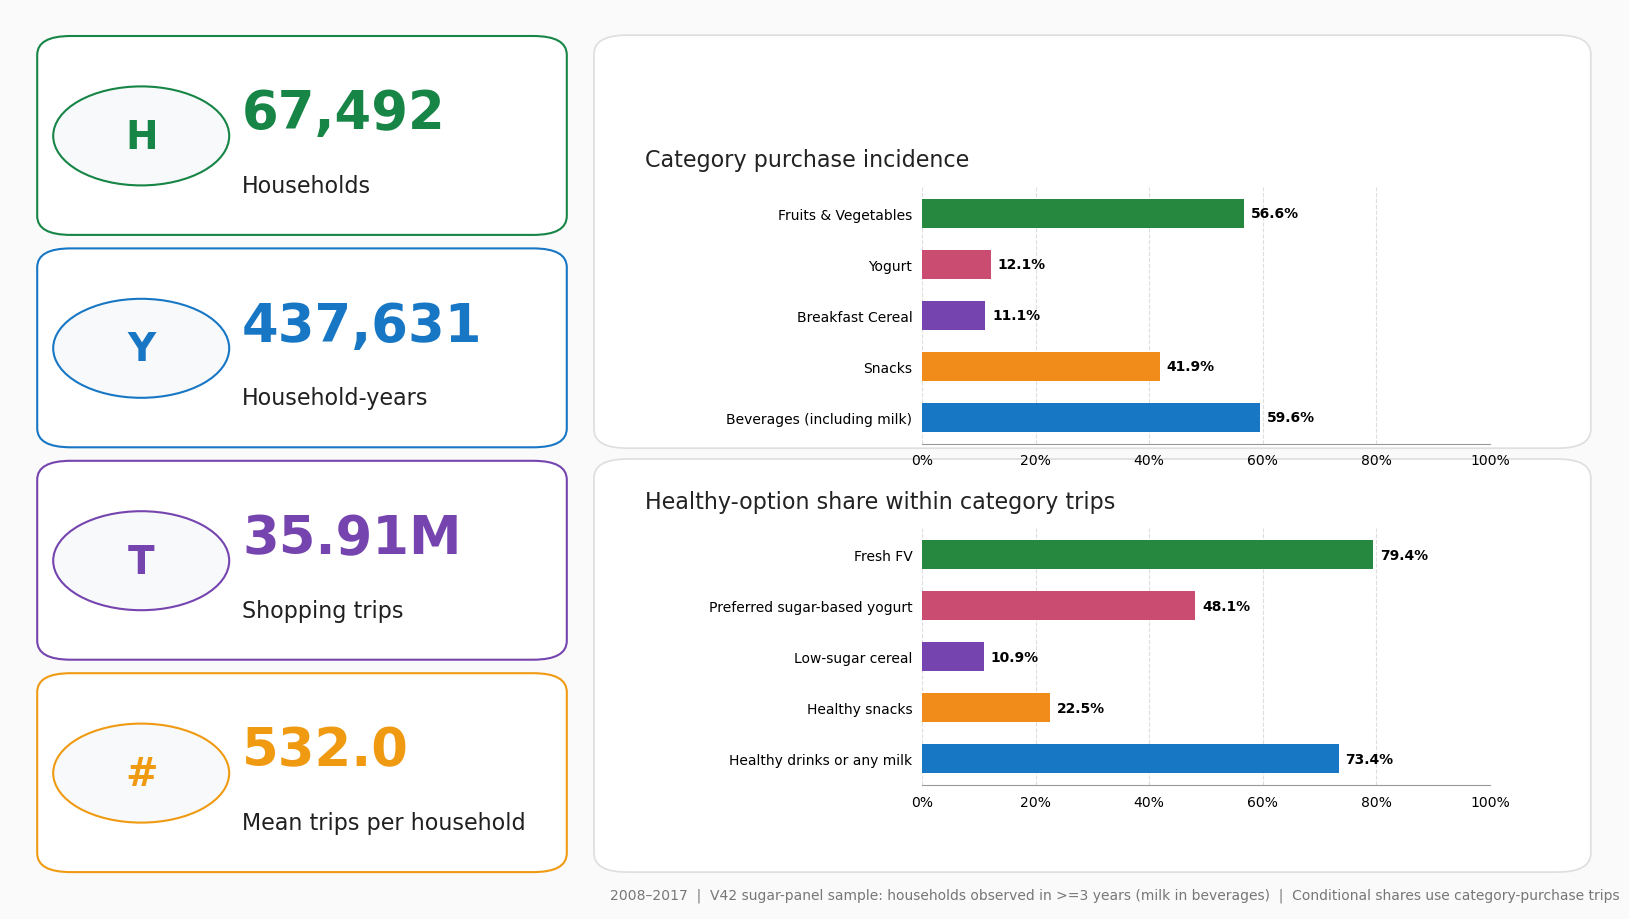

Saved: C:\Users\rwen13\Documents\healthy_purchase_data\model_outputs\descriptive_statistics\V42_sugar_yogurt_three_year\figures\deck_descriptive_figure.png


In [6]:
from matplotlib.patches import FancyBboxPatch, Circle

PALETTE = {"fv": "#26883e", "beverage": "#1877c4", "snack": "#f18c1a",
           "cereal": "#7544af", "yogurt": "#ca4c70"}

fig = plt.figure(figsize=(16, 9), facecolor="#fafafa")
fig.subplots_adjust(0, 0, 1, 1)
background = fig.add_axes([0, 0, 1, 1], zorder=0)
background.axis("off")

def rounded_panel(x, y, w, h, edge="#dfdfdf", fill="#ffffff", linewidth=1.25):
    patch = FancyBboxPatch((x, y), w, h, transform=background.transAxes,
                           boxstyle="round,pad=0.008,rounding_size=0.021",
                           linewidth=linewidth, edgecolor=edge, facecolor=fill)
    background.add_patch(patch)

def kpi_box(bottom, color, number, label, symbol):
    rounded_panel(0.025, bottom, 0.315, 0.205, edge=color, fill="#ffffff", linewidth=1.5)
    background.add_patch(Circle((0.082, bottom + 0.102), 0.055,
                                transform=background.transAxes, facecolor="#f7f9fb",
                                edgecolor=color, linewidth=1.5))
    background.text(0.082, bottom + 0.101, symbol, ha="center", va="center",
                    fontsize=28, color=color, weight="bold", transform=background.transAxes)
    background.text(0.145, bottom + 0.127, number, ha="left", va="center",
                    fontsize=38, weight="bold", color=color, transform=background.transAxes)
    background.text(0.145, bottom + 0.047, label, ha="left", va="center",
                    fontsize=16, color="#202020", transform=background.transAxes)

kpi_box(0.757, "#168546", f"{num_households:,}", "Households", "H")
kpi_box(0.521, "#1877c4", f"{num_hy:,}", "Household-years", "Y")
kpi_box(0.285, "#7544af", f"{num_trips/1_000_000:.2f}M", "Shopping trips", "T")
kpi_box(0.049, "#f09a12", f"{num_trips/num_households:,.1f}", "Mean trips per household", "#")

rounded_panel(0.373, 0.52, 0.607, 0.443)
rounded_panel(0.373, 0.049, 0.607, 0.443)

positions = [(0.47, "Category purchase incidence", "purchase_incidence_pct", "category"),
             (0.091, "Healthy-option share within category trips", "healthy_pct", "healthy_option")]
# Show five V42 emission categories in both right-hand panels.
for top, title, metric, label_col in positions:
    axes = fig.add_axes([0.57, top + 0.047, 0.355, 0.285], zorder=2)
    vals = category_df[metric].to_numpy(float)
    labels = category_df[label_col].tolist()
    keys = category_df["category_key"].tolist()
    y = np.arange(len(keys))
    bars = axes.barh(y, vals, color=[PALETTE[k] for k in keys], height=0.57)
    axes.set_yticks(y, labels=labels, fontsize=10)
    axes.invert_yaxis()
    axes.set_xlim(0, max(100, np.max(vals) + 13))
    axes.set_xticks([0, 20, 40, 60, 80, 100])
    axes.xaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
    axes.grid(axis="x", linestyle="--", color="#dddddd", linewidth=0.8)
    axes.set_axisbelow(True)
    for spine in ["top", "right", "left"]:
        axes.spines[spine].set_visible(False)
    axes.spines["bottom"].set_color("#999999")
    axes.tick_params(axis="both", length=0, pad=7)
    for bar, val in zip(bars, vals):
        axes.text(val + 1.2, bar.get_y() + bar.get_height()/2,
                  f"{val:.1f}%", va="center", ha="left", fontsize=10, weight="bold")
    background.text(0.397, top + 0.355, title, fontsize=16, weight="medium",
                    color="#222222", transform=background.transAxes)

background.text(0.375, 0.012, "2008–2017  |  V42 sugar-panel sample: households observed in >=3 years (milk in beverages)  |  Conditional shares use category-purchase trips",
                fontsize=10, color="#777777", transform=background.transAxes)
figure_path = FIGURE_DIR / "deck_descriptive_figure.png"
# Write the figure into the V38-specific output directory.
fig.savefig(figure_path, dpi=300, facecolor=fig.get_facecolor(), bbox_inches="tight", pad_inches=0.18)
plt.show()
print(f"Saved: {figure_path}")

## 6. Audit and interpretation notes

1. **Alignment:** All panels/plots use the same sugar-panel parquet and the same threshold of ≥3 distinct observed years (2008–2017), with no requirement for consecutive years. If V42's estimation code imposes other eligibility or complete-case exclusions, those must also be applied to reproduce the exact estimation sample.
2. **Filter audit:** `sample_filter_audit.csv` reports household, household-year and trip counts before/after filtering; `beverage_merge_audit.csv` documents combined choice recoding for retained trips.
3. **Panel B:** means and sample SDs weight household-years equally. `K_1` is the child indicator.
4. **Panel C:** category purchase incidence uses all retained trips; within-category outcome percentages use category-purchase trips. These are not expenditure shares.
5. **Panel D:** event percentages are computed after the first observed household-year, including observed-year steps over calendar gaps.
6. **Yogurt:** the outcome is now sugar-based. No old fat-free interpretation is valid; `yogurt_y = 1` is labeled conservatively as the preferred sugar-based option pending verification of the new upstream definition.
7. **Cereal:** classification-based incidence may omit unclassified cereal purchases.
8. **Beverages:** keep combined milk/beverage rule as in V38; milk is not separately modeled.
9. **Initial-state parameter:** no check for a constant `initial_fresh_fv_share_2007` is made because the updated model estimates a free common initial probability.
10. **Data governance:** input parquet, DuckDB temporary files, and locally generated results are outside the Git repository. Only approved aggregate outputs should be shared.
